In [393]:
import pandas as pd
import numpy as np
import torch
from torch import nn
from torchmetrics import Accuracy
from torch import optim
from torch.utils.data import DataLoader, TensorDataset,Dataset
from dotenv import load_dotenv
from datetime import datetime, timedelta
import os
import requests
load_dotenv()

True

In [394]:

headers = {
    "accept": "application/json",
    "x-cg-demo-api-key": str(os.getenv('COIN_API'))
}

In [395]:
response_1 = requests.get(
    "https://api.coingecko.com/api/v3/coins/bitcoin/market_chart?vs_currency=usd&days=90",
    headers=headers
)

data = response_1.json()

# Convert prices to DataFrame
df_prices = pd.DataFrame(data['prices'], columns=['timestamp', 'price'])
df_prices['timestamp'] = pd.to_datetime(df_prices['timestamp'], unit='ms')

# Convert market caps to DataFrame
df_mcap = pd.DataFrame(data['market_caps'], columns=['timestamp', 'market_cap'])
df_mcap['timestamp'] = pd.to_datetime(df_mcap['timestamp'], unit='ms')

# Convert volumes to DataFrame
df_volume = pd.DataFrame(data['total_volumes'], columns=['timestamp', 'volume'])
df_volume['timestamp'] = pd.to_datetime(df_volume['timestamp'], unit='ms')

# Merge all into one DataFrame
df_combined = df_prices.merge(df_mcap, on='timestamp').merge(df_volume, on='timestamp')

# --- Returns (this is your new prediction target) -

df_combined

,timestamp,price,market_cap,volume
0,2026-05-05 19:00:00,81513.456216,1.632318e+12,3.617823e+10
1,2026-05-05 20:00:00,81627.415083,1.634600e+12,3.701947e+10
2,2026-05-05 21:00:00,81644.471711,1.634946e+12,3.715901e+10
3,2026-05-05 22:00:00,81473.677967,1.631526e+12,3.844943e+10
4,2026-05-05 23:00:00,81130.269199,1.624649e+12,3.891131e+10
...,...,...,...,...
2156,2026-08-03 15:00:00,63889.312038,1.281953e+12,2.193575e+10
2157,2026-08-03 16:00:00,63616.510598,1.276480e+12,2.342019e+10
2158,2026-08-03 17:00:00,63711.080959,1.278378e+12,2.422042e+10
2159,2026-08-03 18:00:00,63843.499850,1.281036e+12,2.477577e+10


In [396]:
#values = df_combined[["price", "volume", "market_cap","open",'high','low','close']].to_numpy(dtype=np.float32)
values = df_combined[["price", "volume", "market_cap"]].to_numpy(dtype=np.float32)

train_end = int(len(values) * 0.7)
val_end = int(len(values) * 0.85)

train = values[:train_end]
val = values[train_end:val_end]
test = values[val_end:]

# Fit scaler on TRAIN only
mean = train.mean(axis=0)
std = train.std(axis=0)
std[std == 0] = 1.0

train = (train - mean) / std
val = (val - mean) / std
test = (test - mean) / std

def windows(data, seq_len=30):
    X, y = [], []
    for i in range(len(data) - seq_len):
        X.append(data[i:i + seq_len])
        y.append(data[i + seq_len, 0])  # next price
    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)

X_train, y_train = windows(train)
X_val, y_val = windows(val)
X_test, y_test = windows(test)

print(X_train.shape)
print(X_val.shape)

class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

train_dataset = TimeSeriesDataset(X_train, y_train)
val_dataset = TimeSeriesDataset(X_val, y_val)
test_dataset = TimeSeriesDataset(X_test, y_test)

train_data_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_data_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_data_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


(1482, 30, 3)
(294, 30, 3)


In [397]:
class Model(nn.Module):
    def __init__(self, input_size,hidden_size,num_stacked_layers,batch_first=True):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.num_stacked_layers = num_stacked_layers
        self.lstm = nn.LSTM(self.input_size,hidden_size,self.num_stacked_layers,batch_first=batch_first)
        self.final = nn.Linear(hidden_size,1)

    def forward(self,x):
        batch_size = x.size(0)
        h0 = torch.zeros(self.num_stacked_layers,batch_size,self.hidden_size)
        c0 = torch.zeros(self.num_stacked_layers,batch_size,self.hidden_size)
        out, _ = self.lstm(x,(h0,c0))
        out = self.final(out[:,-1,:])
        return out

model = Model(X_train.shape[-1], hidden_size=5, num_stacked_layers=1)
model

Model(
  (lstm): LSTM(3, 5, batch_first=True)
  (final): Linear(in_features=5, out_features=1, bias=True)
)

In [398]:
def train_model(model, train_loader, val_loader, optimizer, criterion, epoch, num_epochs,training_loss,testing_loss):
    model.train()
    train_loss = 0.0

    for feature, label in train_loader:
        optimizer.zero_grad()
        pred = model(feature).squeeze(-1)
        loss = criterion(pred, label)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)
    training_loss.append(avg_train_loss)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for feature, label in val_loader:
            pred = model(feature).squeeze(-1)
            loss = criterion(pred, label)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)
    testing_loss.append(avg_val_loss)

    print(f"Epoch {epoch + 1}/{num_epochs} - train_loss: {avg_train_loss:.6f} - val_loss: {avg_val_loss:.6f}")

Epoch 1/100 - train_loss: 0.243948 - val_loss: 0.055733
Epoch 2/100 - train_loss: 0.029976 - val_loss: 0.004873
Epoch 3/100 - train_loss: 0.006540 - val_loss: 0.001687
Epoch 4/100 - train_loss: 0.003491 - val_loss: 0.001209
Epoch 5/100 - train_loss: 0.002875 - val_loss: 0.001109
Epoch 6/100 - train_loss: 0.002637 - val_loss: 0.000990
Epoch 7/100 - train_loss: 0.002587 - val_loss: 0.001377
Epoch 8/100 - train_loss: 0.002472 - val_loss: 0.001068
Epoch 9/100 - train_loss: 0.002422 - val_loss: 0.000977
Epoch 10/100 - train_loss: 0.002125 - val_loss: 0.000892
Epoch 11/100 - train_loss: 0.002154 - val_loss: 0.000986
Epoch 12/100 - train_loss: 0.002038 - val_loss: 0.000955
Epoch 13/100 - train_loss: 0.002255 - val_loss: 0.001519
Epoch 14/100 - train_loss: 0.002048 - val_loss: 0.000858
Epoch 15/100 - train_loss: 0.001972 - val_loss: 0.001459
Epoch 16/100 - train_loss: 0.002001 - val_loss: 0.000804
Epoch 17/100 - train_loss: 0.002157 - val_loss: 0.000961
Epoch 18/100 - train_loss: 0.001965 - va

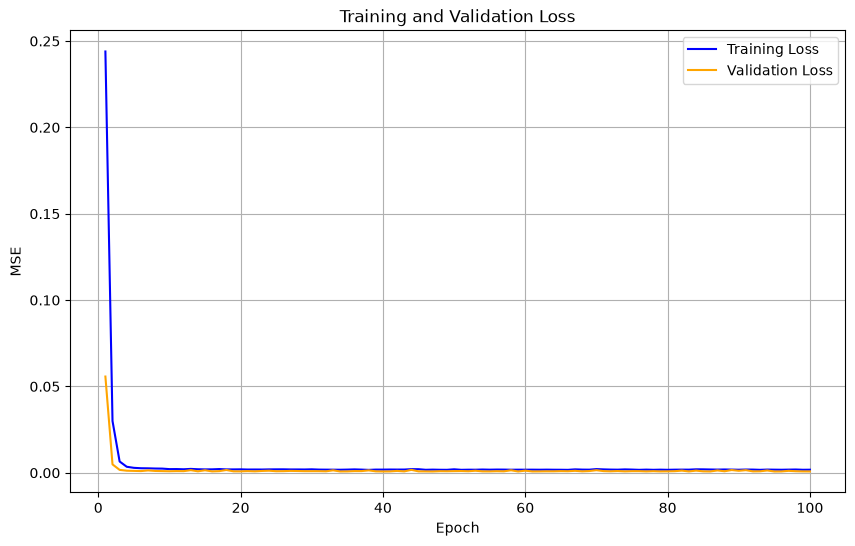

In [399]:
import matplotlib.pyplot as plt

learning_rate = 0.01
num_epochs = 100
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)

training_loss = []
testing_loss = []

for epoch in range(num_epochs):
    train_model(
        model,
        train_data_loader,
        val_data_loader,
        optimizer,
        criterion,
        epoch,
        num_epochs,
        training_loss,
        testing_loss
    )

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(training_loss) + 1), training_loss, label="Training Loss", color="blue")
plt.plot(range(1, len(testing_loss) + 1), testing_loss, label="Validation Loss", color="orange")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [400]:
model.eval()

test_loss = 0.0
with torch.no_grad():
    for feature, label in test_data_loader:
        pred = model(feature).squeeze(-1)
        loss = criterion(pred, label)
        test_loss += loss.item()

avg_test_loss = test_loss / len(test_data_loader)
print(f"Test loss: {avg_test_loss:.6f}")

Test loss: 0.000832


In [401]:
model.eval()

# Save the original price scaling before normalization
price_mean = df_combined["price"].mean()
price_std = df_combined["price"].std()

all_preds = []
all_true = []

with torch.no_grad():
    for feature, label in test_data_loader:
        pred = model(feature).squeeze(-1)
        
        # convert from normalized space back to real price space
        pred_price = pred.cpu().numpy() * price_std + price_mean
        true_price = label.cpu().numpy() * price_std + price_mean
        
        all_preds.append(pred_price)
        all_true.append(true_price)

all_preds = np.concatenate(all_preds)
all_true = np.concatenate(all_true)

# Real dollar-scale metrics
rmse = np.sqrt(np.mean((all_preds - all_true) ** 2))
mae = np.mean(np.abs(all_preds - all_true))

print(f"Test MSE (normalized): {avg_test_loss:.6f}")
print(f"Test RMSE (USD): ${rmse:,.2f}")
print(f"Test MAE (USD): ${mae:,.2f}")

# Optional: print first few predictions
for p, t in zip(all_preds[:5], all_true[:5]):
    print(f"Pred: ${p:,.2f} | Actual: ${t:,.2f}")

Test MSE (normalized): 0.000832
Test RMSE (USD): $189.19
Test MAE (USD): $133.19
Pred: $64,770.40 | Actual: $64,438.76
Pred: $64,416.43 | Actual: $64,720.17
Pred: $64,712.67 | Actual: $64,585.86
Pred: $64,581.19 | Actual: $64,811.43
Pred: $64,819.34 | Actual: $64,980.25


In [402]:
model.eval()
 
# IMPORTANT fix: un-scale with the SAME mean/std the model was trained with
# (the `mean`/`std` arrays from your data-prep cell; index 0 = price column).
# Using df_combined-wide stats biases the USD values by a couple hundred dollars.
price_mean = mean[0]
price_std  = std[0]
 
all_preds = []
all_true = []
all_prev = []   # NEW: the last price the model saw before predicting
 
test_loss = 0.0  # NEW: normalized test loss, computed here so no NameError
 
with torch.no_grad():
    for feature, label in test_data_loader:
        pred = model(feature).squeeze(-1)
        test_loss += criterion(pred, label).item()
 
        # convert from normalized space back to real price space
        pred_price = pred.cpu().numpy() * price_std + price_mean
        true_price = label.cpu().numpy() * price_std + price_mean
 
        # NEW: "previous price" = last step of the window, price is column 0
        prev_price = feature[:, -1, 0].cpu().numpy() * price_std + price_mean
 
        all_preds.append(pred_price)
        all_true.append(true_price)
        all_prev.append(prev_price)
 
all_preds = np.concatenate(all_preds)
all_true  = np.concatenate(all_true)
all_prev  = np.concatenate(all_prev)
 
# Real dollar-scale metrics
rmse = np.sqrt(np.mean((all_preds - all_true) ** 2))
mae  = np.mean(np.abs(all_preds - all_true))
 
# NEW: the hypothesis test — how good is "just copy the previous close"?
copy_rmse  = np.sqrt(np.mean((all_prev - all_true) ** 2))
copy_mae   = np.mean(np.abs(all_prev - all_true))
beats_copy = np.mean(np.abs(all_preds - all_true) < np.abs(all_prev - all_true))
 
print(f"Test MSE (normalized): {test_loss / len(test_data_loader):.6f}")
print(f"Test RMSE (USD): ${rmse:,.2f} | MAE (USD): ${mae:,.2f}")
print(f"Baseline (copy previous close): RMSE ${copy_rmse:,.2f} | MAE ${copy_mae:,.2f}")
print(f"Model beats 'copy previous close' on {beats_copy * 100:.1f}% of test windows")
 
# The table: Prev = last close the model saw | Pred = its guess | Actual = what happened
print("\n  Prev (last seen) |  Predicted   |   Actual")
for p, t, prev in zip(all_preds[:8], all_true[:8], all_prev[:8]):
    print(f"  ${prev:,.2f}   | ${p:,.2f} | ${t:,.2f}")

Test MSE (normalized): 0.000832
Test RMSE (USD): $212.02 | MAE (USD): $149.27
Baseline (copy previous close): RMSE $203.98 | MAE $138.22
Model beats 'copy previous close' on 40.7% of test windows

  Prev (last seen) |  Predicted   |   Actual
  $65,966.71   | $65,961.01 | $65,589.34
  $65,589.34   | $65,564.31 | $65,904.71
  $65,904.71   | $65,896.30 | $65,754.19
  $65,754.19   | $65,748.95 | $66,006.98
  $66,006.98   | $66,015.85 | $66,196.17
  $66,196.17   | $66,220.40 | $65,992.29
  $65,992.29   | $66,003.45 | $65,865.88
  $65,865.88   | $65,862.88 | $65,886.78


In [403]:
#torch.save({
#    "model_state_dict": model.state_dict(),
#    "optimizer_state_dict": optimizer.state_dict(),
#    "learning_rate": learning_rate,
#    "num_epochs": num_epochs,
#    "mean": mean,
#    "std": std,
#    "price_mean": price_mean,
#    "price_std": price_std,
#    "training_loss": training_loss,
#    "testing_loss": testing_loss,
#    "rmse_usd": rmse,
#    "mae_usd": mae
#}, "bitcoin_lstm_model.pt")